# 01 · Exploratory Data Analysis

**Business question:** can we safely approve more applicants who have little or no credit history?

This notebook looks at the raw application table and answers five questions:

1. What does the target look like, and how clean is the data?
2. How big is the **thin-file segment** (no credit bureau history), and how does it differ?
3. Which applicant characteristics are linked to default?
4. How do default rates differ across **protected groups** (gender, age)? This is the baseline for the fairness audit.
5. What history is available for the SecondLook extras: **refused applications** (reject inference) and **repayment sequences** (sequence encoder)?

In [1]:
import sys
from pathlib import Path
sys.path.insert(0, str(Path.cwd().resolve().parent / "src"))  # import secondlook from src/ (no pip install needed)

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

from secondlook.config import FIGURES_DIR, ID_COL, TARGET_COL

sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.max_columns", 60)
FIGURES_DIR.mkdir(parents=True, exist_ok=True)
PALETTE = ["#4C72B0", "#DD8452"]

def savefig(name):
    plt.tight_layout()
    plt.savefig(FIGURES_DIR / f"{name}.png", dpi=150, bbox_inches="tight")

from secondlook.data import list_tables, load_table

## 1. The data
One main table (one row per applicant) and six history tables.

In [2]:
list_tables()

,table,size_mb
0,HomeCredit_columns_description,0.0
1,POS_CASH_balance,392.7
2,application_test,26.6
3,application_train,166.1
4,bureau,170.0
5,bureau_balance,375.6
6,credit_card_balance,424.6
7,installments_payments,723.1
8,previous_application,405.0
9,sample_submission,0.5


In [3]:
app = load_table("application_train")
print(f"{app.shape[0]:,} applicants x {app.shape[1]} columns")
print(f"Default rate (TARGET = 1): {app[TARGET_COL].mean():.2%}")
app.head()

307,511 applicants x 122 columns
Default rate (TARGET = 1): 8.07%


,SK_ID_CURR,TARGET,NAME_CONTRACT_TYPE,CODE_GENDER,FLAG_OWN_CAR,FLAG_OWN_REALTY,CNT_CHILDREN,AMT_INCOME_TOTAL,AMT_CREDIT,AMT_ANNUITY,AMT_GOODS_PRICE,NAME_TYPE_SUITE,NAME_INCOME_TYPE,NAME_EDUCATION_TYPE,NAME_FAMILY_STATUS,NAME_HOUSING_TYPE,REGION_POPULATION_RELATIVE,DAYS_BIRTH,DAYS_EMPLOYED,DAYS_REGISTRATION,DAYS_ID_PUBLISH,OWN_CAR_AGE,FLAG_MOBIL,FLAG_EMP_PHONE,FLAG_WORK_PHONE,FLAG_CONT_MOBILE,FLAG_PHONE,FLAG_EMAIL,OCCUPATION_TYPE,CNT_FAM_MEMBERS,...,DEF_30_CNT_SOCIAL_CIRCLE,OBS_60_CNT_SOCIAL_CIRCLE,DEF_60_CNT_SOCIAL_CIRCLE,DAYS_LAST_PHONE_CHANGE,FLAG_DOCUMENT_2,FLAG_DOCUMENT_3,FLAG_DOCUMENT_4,FLAG_DOCUMENT_5,FLAG_DOCUMENT_6,FLAG_DOCUMENT_7,FLAG_DOCUMENT_8,FLAG_DOCUMENT_9,FLAG_DOCUMENT_10,FLAG_DOCUMENT_11,FLAG_DOCUMENT_12,FLAG_DOCUMENT_13,FLAG_DOCUMENT_14,FLAG_DOCUMENT_15,FLAG_DOCUMENT_16,FLAG_DOCUMENT_17,FLAG_DOCUMENT_18,FLAG_DOCUMENT_19,FLAG_DOCUMENT_20,FLAG_DOCUMENT_21,AMT_REQ_CREDIT_BUREAU_HOUR,AMT_REQ_CREDIT_BUREAU_DAY,AMT_REQ_CREDIT_BUREAU_WEEK,AMT_REQ_CREDIT_BUREAU_MON,AMT_REQ_CREDIT_BUREAU_QRT,AMT_REQ_CREDIT_BUREAU_YEAR
0,100002,1,Cash loans,M,N,Y,0,202500.0,406597.5,24700.5,351000.0,Unaccompanied,Working,Secondary / secondary special,Single / not married,House / apartment,0.018801,-9461,-637,-3648.0,-2120,NaN,1,1,0,1,1,0,Laborers,1.0,...,2.0,2.0,2.0,-1134.0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0.0,0.0,0.0,0.0,0.0,1.0
1,100003,0,Cash loans,F,N,N,0,270000.0,1293502.5,35698.5,1129500.0,Family,State servant,Higher education,Married,House / apartment,0.003541,-16765,-1188,-1186.0,-291,NaN,1,1,0,1,1,0,Core staff,2.0,...,0.0,1.0,0.0,-828.0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0.0,0.0,0.0,0.0,0.0,0.0
2,100004,0,Revolving loans,M,Y,Y,0,67500.0,135000.0,6750.0,135000.0,Unaccompanied,Working,Secondary / secondary special,Single / not married,House / apartment,0.010032,-19046,-225,-4260.0,-2531,26.0,1,1,1,1,1,0,Laborers,1.0,...,0.0,0.0,0.0,-815.0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0.0,0.0,0.0,0.0,0.0,0.0
3,100006,0,Cash loans,F,N,Y,0,135000.0,312682.5,29686.5,297000.0,Unaccompanied,Working,Secondary / secondary special,Civil marriage,House / apartment,0.008019,-19005,-3039,-9833.0,-2437,NaN,1,1,0,1,0,0,Laborers,2.0,...,0.0,2.0,0.0,-617.0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,NaN,NaN,NaN,NaN,NaN,NaN
4,100007,0,Cash loans,M,N,Y,0,121500.0,513000.0,21865.5,513000.0,Unaccompanied,Working,Secondary / secondary special,Single / not married,House / apartment,0.028663,-19932,-3038,-4311.0,-3458,NaN,1,1,0,1,0,0,Core staff,1.0,...,0.0,0.0,0.0,-1106.0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0.0,0.0,0.0,0.0,0.0,0.0


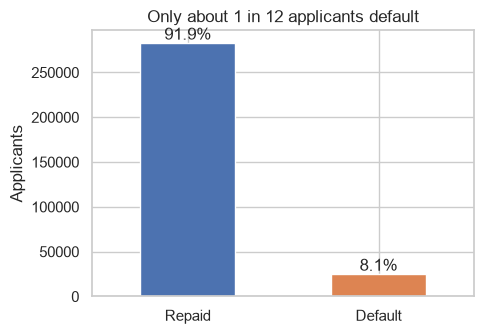

In [4]:
fig, ax = plt.subplots(figsize=(5, 3.5))
counts = app[TARGET_COL].map({0: "Repaid", 1: "Default"}).value_counts()
counts.plot.bar(ax=ax, color=PALETTE)
for i, v in enumerate(counts):
    ax.text(i, v, f"{v / counts.sum():.1%}", ha="center", va="bottom")
ax.set_title("Only about 1 in 12 applicants default"); ax.set_xlabel(""); ax.set_ylabel("Applicants")
ax.tick_params(axis="x", rotation=0)
savefig("01_target_distribution")

**Imbalance matters for evaluation.** A model that predicts "repays" for everyone is 92% accurate and useless,
so we report ROC-AUC and PR-AUC, and judge decisions by approval rate and default rate rather than accuracy.

### Missing values

Columns with any missing values: 67 of 122
Columns more than 50% missing:   41


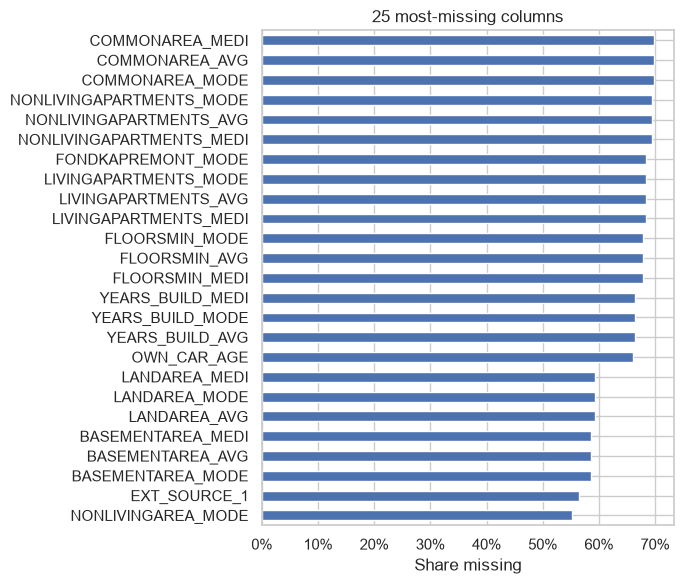

In [5]:
missing = app.isna().mean().sort_values(ascending=False)
print(f"Columns with any missing values: {(missing > 0).sum()} of {app.shape[1]}")
print(f"Columns more than 50% missing:   {(missing > 0.5).sum()}")

fig, ax = plt.subplots(figsize=(7, 6))
missing.head(25).sort_values().plot.barh(ax=ax, color=PALETTE[0])
ax.set_title("25 most-missing columns"); ax.set_xlabel("Share missing")
ax.xaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1.0))
savefig("02_missing_values")

Most of the heavily missing columns describe the applicant's **building** (`*_AVG`, `*_MODE`, `*_MEDI`).
LightGBM handles missing values natively; the logistic baseline will need imputation.

### Known anomaly: `DAYS_EMPLOYED`
Some applicants have `DAYS_EMPLOYED = 365243`, about 1,000 years. It is a placeholder, not a real value.

In [6]:
anom = app["DAYS_EMPLOYED"] == 365243
print(f"Placeholder value: {anom.sum():,} applicants ({anom.mean():.1%})")
print(f"Default rate, placeholder vs rest: {app.loc[anom, TARGET_COL].mean():.2%} vs {app.loc[~anom, TARGET_COL].mean():.2%}")
app.loc[anom, "NAME_INCOME_TYPE"].value_counts().head(3)

Placeholder value: 55,374 applicants (18.0%)
Default rate, placeholder vs rest: 5.40% vs 8.66%


NAME_INCOME_TYPE
Pensioner     55352
Unemployed       22
Name: count, dtype: int64

Almost all of them are pensioners, and they default **less**. So `cleaning.py` replaces the value with
missing *and* keeps a flag (`EMPLOYED_ANOMALY`), rather than throwing the information away.

## 2. The thin-file segment
We define **thin-file** applicants as those with **no rows in `bureau`**: no history with any other lender.
This is the group SecondLook is built for.

In [7]:
bureau_ids = load_table("bureau", usecols=[ID_COL])[ID_COL].unique()
app["THIN_FILE"] = ~app[ID_COL].isin(bureau_ids)

seg = app.groupby("THIN_FILE")[TARGET_COL].agg(applicants="size", default_rate="mean")
seg["share"] = seg["applicants"] / seg["applicants"].sum()
seg.index = seg.index.map({False: "Has bureau history", True: "Thin-file"})
seg.style.format({"applicants": "{:,}", "default_rate": "{:.2%}", "share": "{:.1%}"})

,applicants,default_rate,share
THIN_FILE,,,
Has bureau history,"263,491",7.73%,85.7%
Thin-file,"44,020",10.12%,14.3%


The external credit scores (`EXT_SOURCE_1/2/3`) are among the strongest predictors in this dataset.
If they are missing more often for thin-file applicants, a model that leans on them is least informed exactly where we need it most.

In [8]:
ext = ["EXT_SOURCE_1", "EXT_SOURCE_2", "EXT_SOURCE_3"]
miss_ext = app.groupby("THIN_FILE")[ext].apply(lambda d: d.isna().mean())
miss_ext.index = miss_ext.index.map({False: "Has bureau history", True: "Thin-file"})
miss_ext.style.format("{:.1%}")

,EXT_SOURCE_1,EXT_SOURCE_2,EXT_SOURCE_3
THIN_FILE,,,
Has bureau history,55.6%,0.2%,6.9%
Thin-file,60.8%,0.3%,96.9%


## 3. What is linked to default?

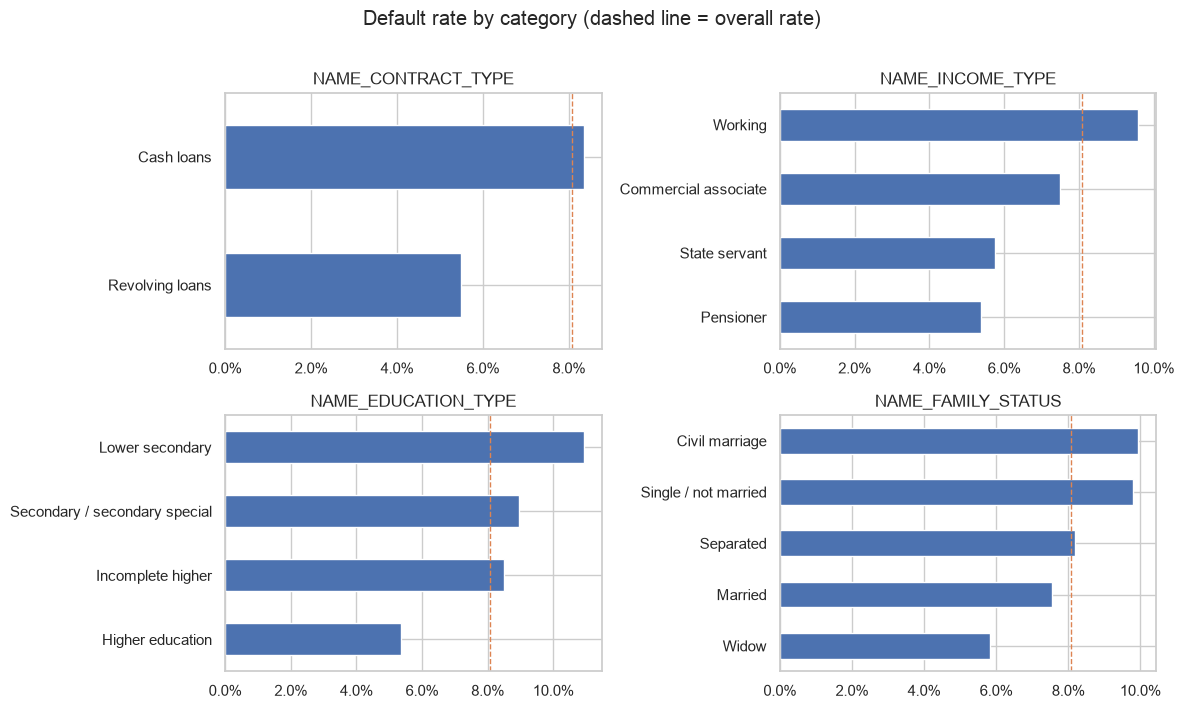

In [9]:
cats = ["NAME_CONTRACT_TYPE", "NAME_INCOME_TYPE", "NAME_EDUCATION_TYPE", "NAME_FAMILY_STATUS"]
fig, axes = plt.subplots(2, 2, figsize=(12, 7))
for ax, col in zip(axes.flat, cats):
    rate = app.groupby(col)[TARGET_COL].mean().sort_values()
    n = app[col].value_counts()
    rate = rate[n[rate.index] >= 500]  # hide tiny groups
    rate.plot.barh(ax=ax, color=PALETTE[0])
    ax.axvline(app[TARGET_COL].mean(), color=PALETTE[1], ls="--", lw=1)
    ax.set_title(col); ax.set_ylabel("")
    ax.xaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1.0))
fig.suptitle("Default rate by category (dashed line = overall rate)", y=1.01)
savefig("03_default_rate_by_category")

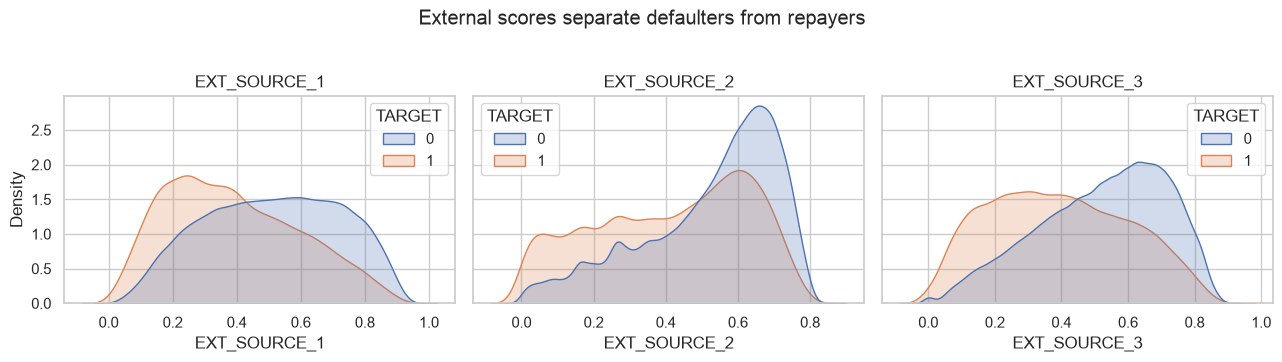

In [10]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.5), sharey=True)
for ax, col in zip(axes, ext):
    sns.kdeplot(data=app, x=col, hue=TARGET_COL, common_norm=False, fill=True, ax=ax, palette=PALETTE)
    ax.set_title(col)
fig.suptitle("External scores separate defaulters from repayers", y=1.03)
savefig("04_kde_ext_sources")

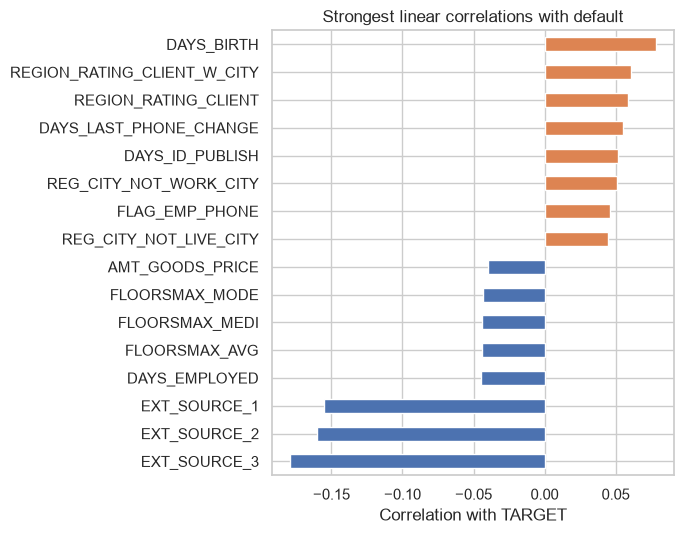

In [11]:
num = app.select_dtypes("number").drop(columns=[ID_COL, TARGET_COL])
corr = num.corrwith(app[TARGET_COL]).dropna().sort_values()
top = pd.concat([corr.head(8), corr.tail(8)])

fig, ax = plt.subplots(figsize=(7, 5.5))
top.plot.barh(ax=ax, color=[PALETTE[0] if v < 0 else PALETTE[1] for v in top])
ax.set_title("Strongest linear correlations with default"); ax.set_xlabel("Correlation with TARGET")
savefig("05_target_correlations")

## 4. Protected groups (baseline for the fairness audit)
Gender and age are **never model inputs**. We look at them only to know the starting point:
if default rates differ by group, a model can still pick those differences up through correlated features,
so we will audit the model's decisions by group in notebook 08.

In [12]:
by_gender = app.groupby("CODE_GENDER")[TARGET_COL].agg(applicants="size", default_rate="mean")
by_gender.style.format({"applicants": "{:,}", "default_rate": "{:.2%}"})

,applicants,default_rate
CODE_GENDER,,
F,"202,448",7.00%
M,"105,059",10.14%
XNA,4,0.00%


,applicants,default_rate
AGE_BAND,,
"[18, 30)","45,186",11.44%
"[30, 40)","82,331",9.59%
"[40, 50)","76,599",7.64%
"[50, 60)","68,094",6.12%
"[60, 70)","35,301",4.92%


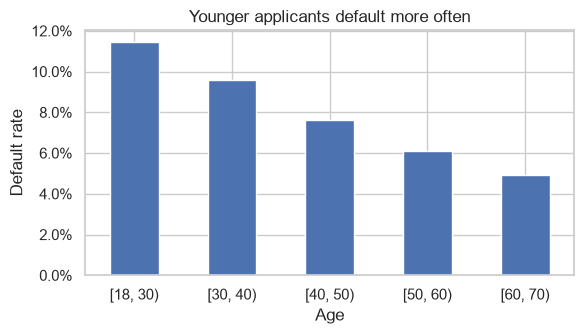

In [13]:
app["AGE_YEARS"] = -app["DAYS_BIRTH"] / 365.25
app["AGE_BAND"] = pd.cut(app["AGE_YEARS"], bins=[18, 30, 40, 50, 60, 70], right=False)
by_age = app.groupby("AGE_BAND", observed=True)[TARGET_COL].agg(applicants="size", default_rate="mean")

fig, ax = plt.subplots(figsize=(6, 3.5))
by_age["default_rate"].plot.bar(ax=ax, color=PALETTE[0])
ax.set_title("Younger applicants default more often"); ax.set_xlabel("Age"); ax.set_ylabel("Default rate")
ax.yaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1.0))
ax.tick_params(axis="x", rotation=0)
savefig("06_default_by_age")
by_age.style.format({"applicants": "{:,}", "default_rate": "{:.2%}"})

## 5. History available for the SecondLook extras

### Refused applications (reject inference, notebook 06)
`application_train` only contains loans that were **granted**. `previous_application` also records
applications that were **refused**, which lets us correct for that bias.

In [14]:
prev = load_table("previous_application", usecols=[ID_COL, "NAME_CONTRACT_STATUS"])
print(f"{len(prev):,} previous applications from {prev[ID_COL].nunique():,} applicants")
prev["NAME_CONTRACT_STATUS"].value_counts(normalize=True).to_frame("share").style.format("{:.1%}")

1,670,214 previous applications from 338,857 applicants


,share
NAME_CONTRACT_STATUS,
Approved,62.1%
Canceled,18.9%
Refused,17.4%
Unused offer,1.6%


In [15]:
refused_ids = prev.loc[prev["NAME_CONTRACT_STATUS"] == "Refused", ID_COL].unique()
app["PRIOR_REFUSAL"] = app[ID_COL].isin(refused_ids)
pr = app.groupby(["THIN_FILE", "PRIOR_REFUSAL"])[TARGET_COL].agg(applicants="size", default_rate="mean")
pr.style.format({"applicants": "{:,}", "default_rate": "{:.2%}"})

### Repayment sequences (sequence encoder, notebook 07)
`installments_payments` has one row per installment paid on earlier Home Credit loans.
Thin-file applicants have no bureau history, but many do have repayment history **with Home Credit itself**.

In [16]:
inst = load_table("installments_payments", usecols=[ID_COL])
seq_len = inst.groupby(ID_COL).size()
app["N_INSTALLMENTS"] = app[ID_COL].map(seq_len).fillna(0).astype(int)
has_hist = app["N_INSTALLMENTS"] > 0

print(f"Applicants with any repayment history: {has_hist.mean():.1%}")
print(f"  ...among thin-file applicants:        {has_hist[app['THIN_FILE']].mean():.1%}")
print(app.loc[has_hist, "N_INSTALLMENTS"].describe(percentiles=[0.25, 0.5, 0.75, 0.95]).round(1).to_string())

Applicants with any repayment history: 94.8%
  ...among thin-file applicants:        94.6%
count    291643.0
mean         39.7
std          40.7
min           1.0
25%          12.0
50%          25.0
75%          51.0
95%         130.0
max         372.0


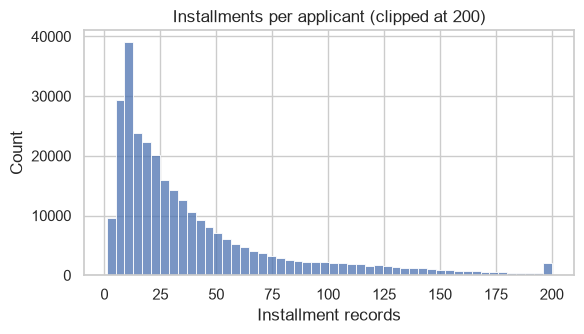

In [17]:
fig, ax = plt.subplots(figsize=(6, 3.5))
sns.histplot(app.loc[has_hist, "N_INSTALLMENTS"].clip(upper=200), bins=50, ax=ax, color=PALETTE[0])
ax.set_title("Installments per applicant (clipped at 200)"); ax.set_xlabel("Installment records")
savefig("07_installment_sequence_lengths")

## Summary

In [18]:
summary = pd.Series({
    "Applicants": f"{len(app):,}",
    "Default rate": f"{app[TARGET_COL].mean():.2%}",
    "Thin-file share": f"{app['THIN_FILE'].mean():.1%}",
    "Default rate, thin-file": f"{app.loc[app['THIN_FILE'], TARGET_COL].mean():.2%}",
    "Default rate, has bureau history": f"{app.loc[~app['THIN_FILE'], TARGET_COL].mean():.2%}",
    "Applicants with a prior refusal": f"{app['PRIOR_REFUSAL'].mean():.1%}",
    "Thin-file with repayment history": f"{has_hist[app['THIN_FILE']].mean():.1%}",
})
summary.to_frame("value")

,value
Applicants,"307,511"
Default rate,8.07%
Thin-file share,14.3%
"Default rate, thin-file",10.12%
"Default rate, has bureau history",7.73%
Applicants with a prior refusal,32.6%
Thin-file with repayment history,94.6%


### Takeaways

1. **Imbalanced target.** 8.07% of 307,511 applicants defaulted, so we evaluate with ROC-AUC, PR-AUC and approval/default rates, not accuracy.
2. **Thin-file is a real, sizeable segment.** 14.3% of applicants (44,020) have no credit bureau history. They default more often (10.1% vs 7.7%), but most of them still repay. That is the opportunity.
3. **Standard scores go blind on thin-file applicants.** `EXT_SOURCE_3`, one of the strongest predictors, is missing for **96.9%** of thin-file applicants vs 6.9% of everyone else (it behaves like a bureau-based score). A model leaning on it is least informed exactly where SecondLook needs to work.
4. **Alternative data fills the gap.** 94.6% of thin-file applicants have repayment history on earlier Home Credit loans, a median of 25 installments each. This drives the SQL history features (notebook 02) and the sequence encoder (notebook 07).
5. **`DAYS_EMPLOYED` placeholder.** 18.0% of applicants (almost all pensioners) have a placeholder value; they default *less* (5.4% vs 8.7%), so we keep it as a flag rather than dropping it.
6. **Protected groups differ at baseline.** Men default more than women (10.1% vs 7.0%) and default falls steadily with age (11.4% under 30 to 4.9% at 60+). Neither is a model input, but correlated features can carry these gaps, so notebook 08 audits decisions by group.
7. **Refused applications are available for reject inference.** 32.6% of applicants had at least one refused application before; those with a prior refusal default more (13.5% vs 8.9% among thin-file), which notebook 06 uses to correct the approved-only bias.